# Assignment 3: Denoising Autoencoder on MNIST

In [1]:
import os
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NOISE_STD = 0.5
EPOCHS = 20
BATCH_SIZE = 256
os.makedirs("outputs", exist_ok=True)

## 1. Data Preparation

In [2]:
train_set = datasets.MNIST("data", train=True, download=True)
test_set = datasets.MNIST("data", train=False, download=True)

# normalize to [0, 1] and flatten 28x28 -> 784
x_train = train_set.data.float().div(255).view(-1, 784)
x_test = test_set.data.float().div(255).view(-1, 784)

def add_noise(x):
    return (x + NOISE_STD * torch.randn_like(x)).clamp(0, 1)

x_train_noisy = add_noise(x_train)
x_test_noisy = add_noise(x_test)

print("Clean train:", x_train.shape, "| Noisy train:", x_train_noisy.shape)
print("Noisy range:", x_train_noisy.min().item(), "to", x_train_noisy.max().item())

Clean train: torch.Size([60000, 784]) | Noisy train: torch.Size([60000, 784])
Noisy range: 0.0 to 1.0


## 2. Autoencoder Architecture

In [3]:
model = nn.Sequential(
    # encoder
    nn.Linear(784, 256), nn.ReLU(),
    nn.Linear(256, 128), nn.ReLU(),  # bottleneck
    # decoder
    nn.Linear(128, 256), nn.ReLU(),
    nn.Linear(256, 784), nn.Sigmoid(),
).to(device)
print(model)

Sequential(
  (0): Linear(in_features=784, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=256, bias=True)
  (5): ReLU()
  (6): Linear(in_features=256, out_features=784, bias=True)
  (7): Sigmoid()
)


## 3. Training

In [4]:
optimizer = torch.optim.Adam(model.parameters())
loss_fn = nn.MSELoss()
train_loader = DataLoader(TensorDataset(x_train_noisy, x_train), batch_size=BATCH_SIZE, shuffle=True)

for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0
    for noisy, clean in train_loader:
        noisy, clean = noisy.to(device), clean.to(device)
        loss = loss_fn(model(noisy), clean)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(noisy)

    model.eval()
    with torch.no_grad():
        test_loss = loss_fn(model(x_test_noisy.to(device)), x_test.to(device)).item()
    print(f"Epoch {epoch:2d} | train loss {total / len(x_train):.4f} | test loss {test_loss:.4f}")

Epoch  1 | train loss 0.0648 | test loss 0.0409


Epoch  2 | train loss 0.0357 | test loss 0.0307


Epoch  3 | train loss 0.0288 | test loss 0.0263


Epoch  4 | train loss 0.0252 | test loss 0.0235


Epoch  5 | train loss 0.0228 | test loss 0.0215


Epoch  6 | train loss 0.0212 | test loss 0.0204


... (10 outputs left out)

Epoch 17 | train loss 0.0152 | test loss 0.0155


Epoch 18 | train loss 0.0150 | test loss 0.0152


Epoch 19 | train loss 0.0148 | test loss 0.0152


Epoch 20 | train loss 0.0146 | test loss 0.0150


## 4. Results and Analysis

In [5]:
with torch.no_grad():
    x_test_recon = model(x_test_noisy.to(device)).cpu()

print(f"MSE noisy input vs clean:   {loss_fn(x_test_noisy, x_test).item():.4f}")
print(f"MSE reconstruction vs clean: {loss_fn(x_test_recon, x_test).item():.4f}")

MSE noisy input vs clean:   0.1157
MSE reconstruction vs clean: 0.0150


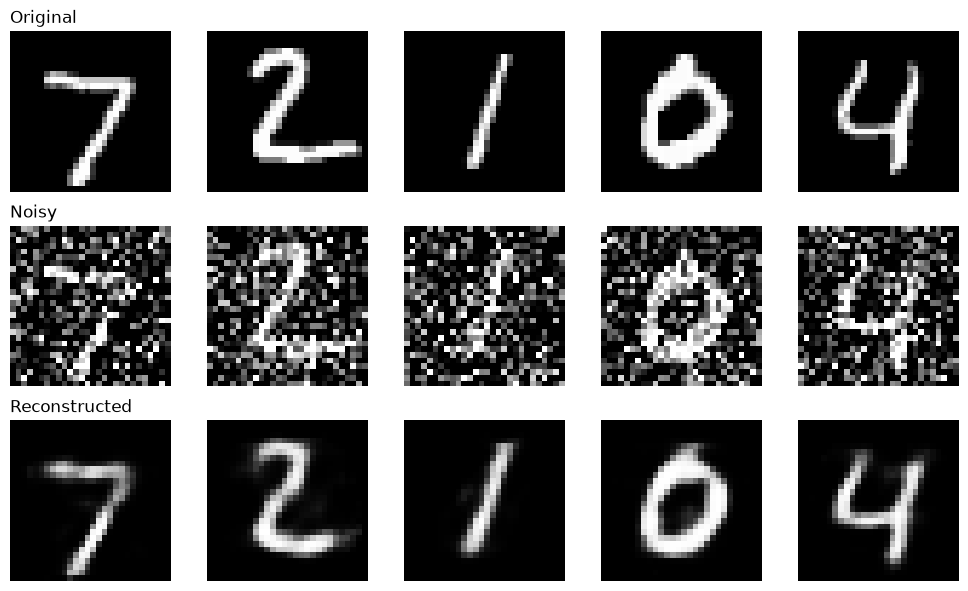

In [6]:
n = 5
rows = [("Original", x_test), ("Noisy", x_test_noisy), ("Reconstructed", x_test_recon)]

fig, axes = plt.subplots(3, n, figsize=(2 * n, 6))
for r, (title, imgs) in enumerate(rows):
    for i in range(n):
        axes[r, i].imshow(imgs[i].view(28, 28), cmap="gray")
        axes[r, i].axis("off")
    axes[r, 0].set_title(title, loc="left")
plt.tight_layout()
plt.savefig("outputs/results.png")
plt.show()

The DAE cuts the test MSE from about 0.116 (noisy input vs clean) to about 0.015 (reconstruction vs clean). Train and test loss stay close throughout, so the model is not overfitting.

The reconstructions are clean digits with the background noise fully removed, which shows that the 128-unit bottleneck learns the structure of the digits rather than copying pixels. They are slightly blurrier than the originals, which is expected from an MSE loss, since it averages over plausible pixel values.